<a href="https://colab.research.google.com/github/Symon-CNA/CNA/blob/main/Newton_Modificado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

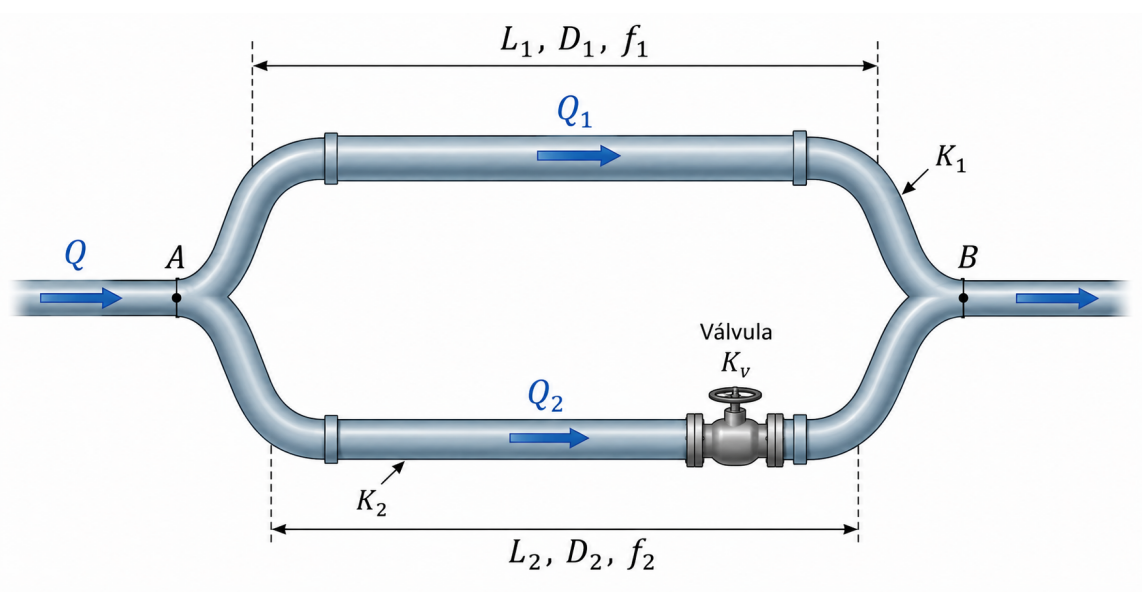

In [ ]:
import numpy as np

# Parametros do Problema
Q = 0.050  # Vazão total [m³/s]
g = 9.81         # Aceleração da gravidade [m/s²]

# Ramo 1
L1 = 30.0        # Comprimento [m]
D1 = 0.10        # Diâmetro [m]
f1 = 0.020       # Fator de atrito
K1 = 1.5         # Perda localizada

# Ramo 2
L2 = 20.0        # Comprimento [m]
D2 = 0.08        # Diâmetro [m]
f2 = 0.022       # Fator de atrito
K2 = 1.0         # Perda localizada
Kv = 8.0         # Perda localizada da válvula

# Calculo dos Coeficientes R1 e R2
R1 = (f1*(L1/D1)+K1)*(8/(g*(np.pi**2)*D1**4))
R2 = (f2*(L2/D2)+K2 + Kv)*(8/(g*(np.pi**2)*D2**4))

print(f"Coeficiente R1: {R1:.2f} s²/m⁵")
print(f"Coeficiente R2: {R2:.2f} s²/m⁵")
print("=" * 75)

# Parametros do Metodo de Newthon-Raphson
Q1 = 0.030       # Chute inicial Q1 [m³/s]
Q2 = 0.020       # Chute inicial Q2 [m³/s]
tol = 1e-8       # Tolerância de convergência [m³/s]
max_iter = 50    # Número máximo de iterações

# Cabeçalho da tabela de acompanhamento
print(f"{'k':<3} | {'Q1 (m³/s)':<11} | {'Q2 (m³/s)':<11} | {'F1 (m³/s)':<12} | {'F2 (m²/s²)':<12} | {'dQ1 (m³/s)':<11} | {'dQ2 (m³/s)':<11}")
print("-" * 88)

# Laço iterativo de Newton-Raphson
convergiu = False

for k in range(max_iter):
  # 1. Avaliação dos residuos
  F1 = Q1 + Q2 - Q
  F2 = R1*(Q1**2) - R2*(Q2**2)

  # 2. Avaliação dos elementos da Matriz Jacobiana
  # J = [[a, b], [c, d]]
  a = 1
  b = 1
  c = 2*Q1*R1
  d = -2*Q2*R2

  # Resíduos para o sistema linear (J * dQ = -F)
  r1 = -F1
  r2 = -F2

  # 3. Solução do sistema 2x2 pela Regra de Cramer
  D = a*d - b*c
  deltaQ1 = (r1*d - r2*b)/D
  deltaQ2 = (r2*a - r1*c)/D

  # Impressão do histórico da iteração atual
  print(f"{k:<3} | {Q1:<11.8f} | {Q2:<11.8f} | {F1:<12.4e} | {F2:<12.4e} | {deltaQ1:<11.4e} | {deltaQ2:<11.4e}")

  # 4. Verificação do critério de convergência
  if max(abs(deltaQ1), abs(deltaQ2)) < tol:
    convergiu = True
    break

  # 5. Atualização das Variáveis
  Q1 += deltaQ1
  Q2 = deltaQ2

print("=" * 88)

if convergiu:
    print(f"Convergência atingida na iteração {k}!")
else:
    print("O método não convergiu dentro do número máximo de iterações.")

# Verificação dis Resultados Finais
U1 = 4*Q1/(np.pi*D1**2)
U2 = 4*Q2/(np.pi*D2**2)

Hl1 = R1*Q1**2
Hl2 = R2*Q2**2

print("\n--- RESULTADOS FINAIS ---")
print(f"Vazão Ramo 1 (Q1)     : {Q1:.6f} m³/s ({Q1/Q*100:.2f}%)")
print(f"Vazão Ramo 2 (Q2)     : {Q2:.6f} m³/s ({Q2/Q*100:.2f}%)")
print(f"Velocidade Ramo 1 (U1): {U1:.4f} m/s")
print(f"Velocidade Ramo 2 (U2): {U2:.4f} m/s")
print("\n--- VERIFICAÇÃO FÍSICA ---")
print(f"Soma das vazões (Q1 + Q2) : {Q1 + Q2:.6f} m³/s (Esperado: {Q:.6f})")
print(f"Perda de carga Ramo 1 (hL1): {Hl1:.4f} m")
print(f"Perda de carga Ramo 2 (hL2): {Hl2:.4f} m")
print(f"Diferença entre perdas     : {abs(Hl1 - Hl2):.4e} m")



**Questões Para Discussão**

**a)** Qual dos dois ramos transporta a maior parcela da vazão total? Relacione o resultado com os valores de R1 e R2.

**b)** Qual foi o número de iterações necessárias para a convergência?

**c)** Os valores finais satisfazem a conservação da vazão? E a igualdade das perdas de carga?

**d)** Por que o método de Newton–Raphson transforma, a cada iteração, o sistema não
linear original em um sistema linear?

**e)** Qual é o papel da matriz Jacobiana nesse processo de linearização?

**f)** Repita a solução utilizando estimativas iniciais diferentes. O método converge para a mesma solução? O número de iterações se altera?
